IBM HR ANALYTICS EMPLOYEE ATTRITION & PERFORMANCE

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

In [3]:
warnings.filterwarnings('ignore')
sns.set_theme(style = "whitegrid", palette = "muted")

Filterwarnigns remove the warnings that can be shown by the python interpreter. It is not an error state but a warning that does not stop the background code from running as well. We just remove the warnings from displaying 

In [4]:
data = pd.read_csv("DATA/IBM_HR_Dataset.csv")
df = data.copy()
df.shape

(1470, 35)

In [5]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [8]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [9]:
print("Rows:", df.shape[0])
print("\nColumns:", df.shape[1])
print("\nCategorical columns:", df.select_dtypes(include = "object").columns.tolist())
print("\nNumeric columns", df.select_dtypes(include = "number").columns.tolist())

Rows: 1470

Columns: 35

Categorical columns: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

Numeric columns ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [10]:
df['Attrition'].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

## Dataset Summary

- 1470 rows, 35 columns
- No missing values across any column
- Target variable: `Attrition` (binary — Yes/No)
- Class imbalance: 84% No, 16% Yes — model accuracy alone is misleading
- 4 constant/ID columns identified for removal: `EmployeeCount`, `StandardHours`, `Over18`, `EmployeeNumber`
- 8 ordinal scale columns disguised as numeric: Education, EnvironmentSatisfaction, etc.

In [11]:
df['Attrition'].value_counts(normalize = True).round(3) * 100

Attrition
No     83.9
Yes    16.1
Name: proportion, dtype: float64

- Class imbalance: 83.9% No, 16.1% Yes

In [12]:
df[['Attrition', 'MonthlyRate', 'MonthlyIncome']]

,Attrition,MonthlyRate,MonthlyIncome
0,Yes,19479,5993
1,No,24907,5130
2,Yes,2396,2090
3,No,23159,2909
4,No,16632,3468
...,...,...,...
1465,No,12290,2571
1466,No,21457,9991
1467,No,5174,6142
1468,No,13243,5390


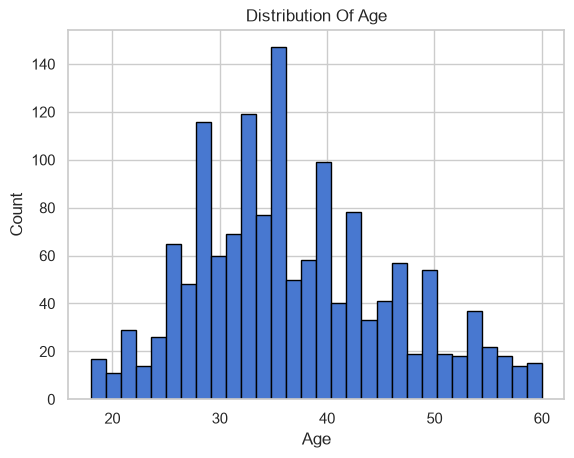

In [13]:
df['Age'].hist(bins = 30, edgecolor = 'black')
plt.title("Distribution Of Age")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

### Age Distribution
- Most employees are between 25-40 years old
- Slight right skew — workforce skews young
- Business insight: younger workforce means higher attrition risk — more market mobility and career ambition
- Hypothesis forming: younger employees may have higher attrition rates

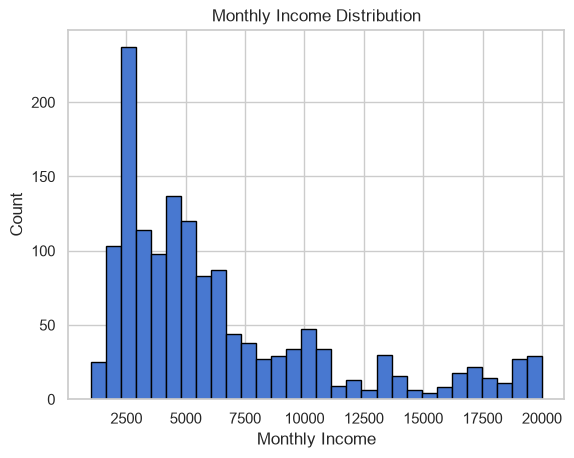

In [14]:
df['MonthlyIncome'].hist(bins = 30, edgecolor = 'Black')
plt.title('Monthly Income Distribution')
plt.xlabel('Monthly Income')
plt.ylabel('Count')
plt.show()

### Monthly Income Distribution
- Strong positive skew — most employees earn on the lower end, few high earners
- Mean is misleading here — median is a better central tendency measure
- Log transformation will be applied during feature engineering

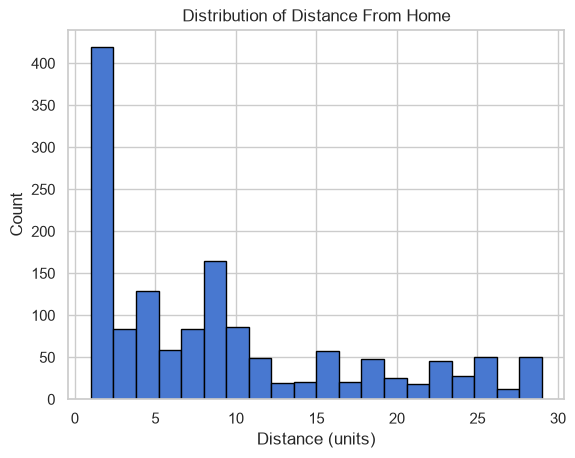

In [15]:
df['DistanceFromHome'].hist(bins=20, edgecolor='black')
plt.title('Distribution of Distance From Home')
plt.xlabel('Distance (units)')
plt.ylabel('Count')
plt.show()

### Distance From Home
- Highly positively skewed — majority live close to work
- Hypothesis: employees with longer commutes may show higher attrition


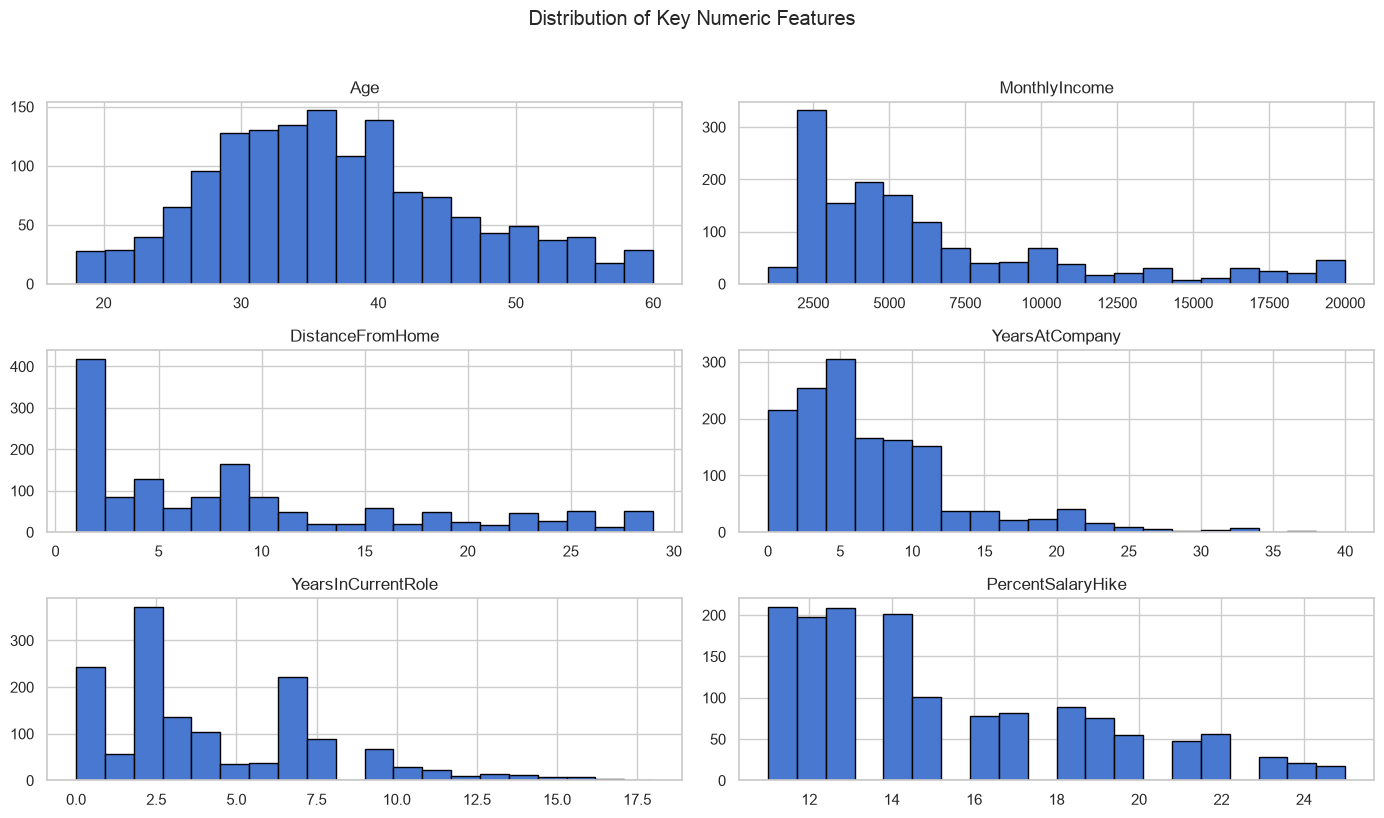

In [16]:
numeric_cols = ['Age', 'MonthlyIncome', 'DistanceFromHome', 
                'YearsAtCompany', 'YearsInCurrentRole', 'PercentSalaryHike']

df[numeric_cols].hist(bins=20, figsize=(14, 8), edgecolor='black')
plt.suptitle('Distribution of Key Numeric Features', y=1.02)
plt.tight_layout()
plt.show()

| Column | Distribution |
|---|---|
| `Age` | Approximately normal, slight right skew |
| `MonthlyIncome` | Strong positive skew |
| `DistanceFromHome` | Strong positive skew |
| `YearsAtCompany` | Positive skew |
| `YearsInCurrentRole` | Positive skew |
| `PercentSalaryHike` | Positive skew |

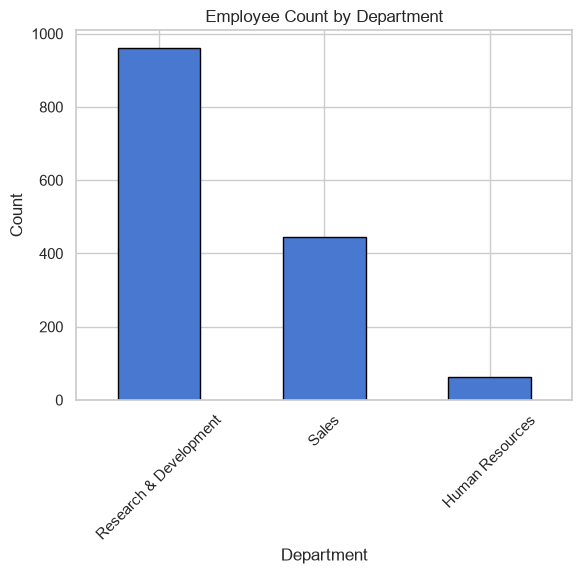

In [17]:
df['Department'].value_counts().plot(kind = 'bar', edgecolor = 'black')
plt.title('Employee Count by Department')
plt.xlabel('Department')
plt.ylabel('Count')
plt.xticks(rotation = 45)
plt.show()

### Department Distribution
- R&D dominates (~65% of workforce)
- Sales is second (~28%)
- HR is very small (~7%)
- Attrition patterns likely vary significantly across departments

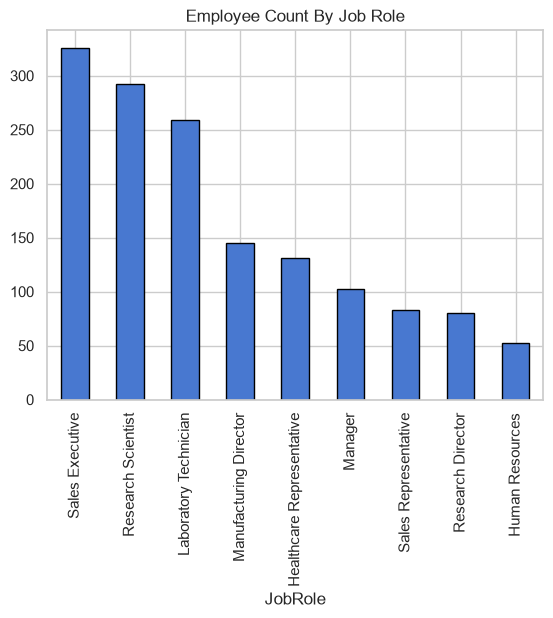

In [18]:
df['JobRole'].value_counts().plot(kind = 'bar', edgecolor = 'Black')
plt.title("Employee Count By Job Role")
plt.xticks(rotation = 90)
plt.show()

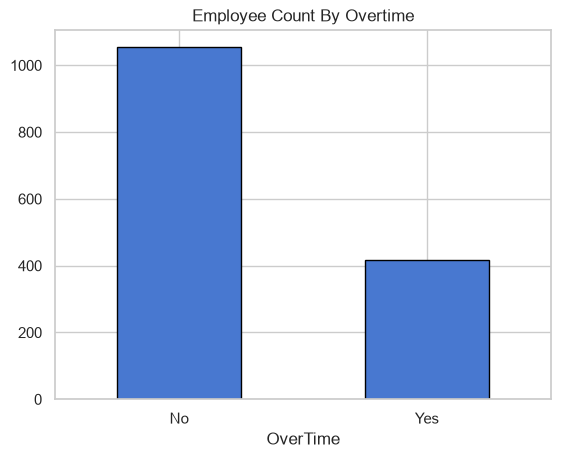

In [19]:
df['OverTime'].value_counts().plot(kind = 'bar', edgecolor = 'black')
plt.title("Employee Count By Overtime")
plt.xticks(rotation = 0)
plt.show()

### Overtime Distribution
- 72% No overtime, 28% Yes overtime
- Hypothesis: employees working overtime are significantly more likely to leave
- This will likely be one of the strongest attrition predictors

In [20]:
df['Attrition'] = df['Attrition'].map({"Yes" : 1, "No" : 0})
df['Attrition'].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

In [21]:
corr_matrix = df.corr(numeric_only = True)

In [22]:
corr_matrix['Attrition'].sort_values(ascending = False)

Attrition                   1.000000
DistanceFromHome            0.077924
NumCompaniesWorked          0.043494
MonthlyRate                 0.015170
PerformanceRating           0.002889
HourlyRate                 -0.006846
EmployeeNumber             -0.010577
PercentSalaryHike          -0.013478
Education                  -0.031373
YearsSinceLastPromotion    -0.033019
RelationshipSatisfaction   -0.045872
DailyRate                  -0.056652
TrainingTimesLastYear      -0.059478
WorkLifeBalance            -0.063939
EnvironmentSatisfaction    -0.103369
JobSatisfaction            -0.103481
JobInvolvement             -0.130016
YearsAtCompany             -0.134392
StockOptionLevel           -0.137145
YearsWithCurrManager       -0.156199
Age                        -0.159205
MonthlyIncome              -0.159840
YearsInCurrentRole         -0.160545
JobLevel                   -0.169105
TotalWorkingYears          -0.171063
EmployeeCount                    NaN
StandardHours                    NaN
N

### Correlation with Attrition
- Pearson correlation is weak across all features (max -0.17) due to binary nature of target
- Strongest negative correlations: TotalWorkingYears, JobLevel, MonthlyIncome, YearsInCurrentRole, Age
- Strongest positive correlations: DistanceFromHome, NumCompaniesWorked
- EmployeeCount and StandardHours return NaN — confirmed useless constants
- Conclusion: correlation alone is insufficient — bivariate plots needed to reveal true relationships

In [23]:
corr_vals = df.corr(numeric_only = True)['Attrition'].drop('Attrition').sort_values()

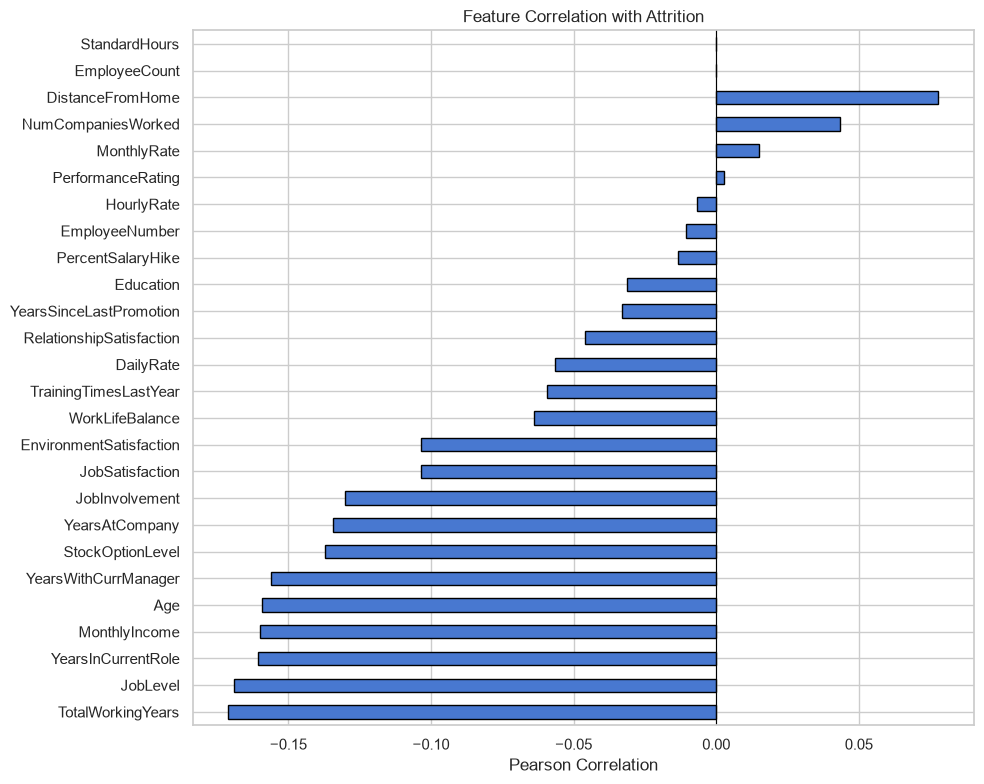

In [24]:
plt.figure(figsize= (10,8))
corr_vals.plot(kind = 'barh', edgecolor = 'black')
plt.title('Feature Correlation with Attrition')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


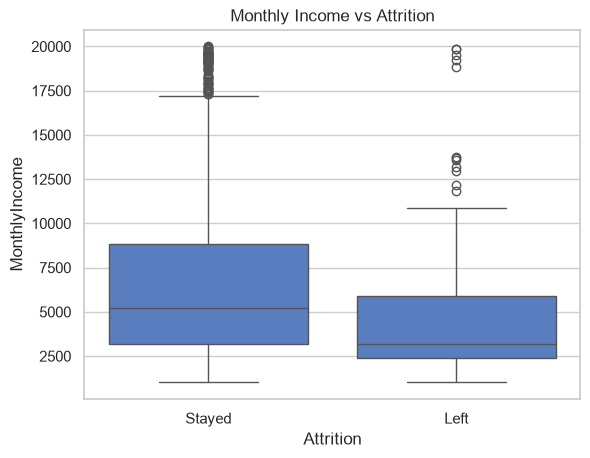

In [25]:
sns.boxplot(data = df, x = 'Attrition', y = 'MonthlyIncome')
plt.title('Monthly Income vs Attrition')
plt.xticks([0, 1], ['Stayed', 'Left'])
plt.show()

### Monthly Income vs Attrition
- Median income of employees who left (~2750) is almost half of those who stayed (~5000)
- Clear and strong signal — low compensation is a primary attrition driver
- Insight: employees earning below the company median are at significantly higher attrition risk

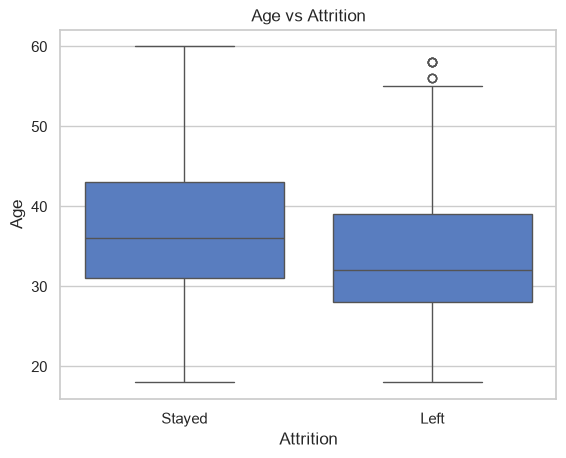

In [26]:
sns.boxplot(data=df, x='Attrition', y='Age')
plt.title('Age vs Attrition')
plt.xticks([0, 1], ['Stayed', 'Left'])
plt.show()

### Age vs Attrition
- Median age of employees who left (~32) is lower than those who stayed (~35)
- Younger employees are more likely to leave — more market mobility, less loyalty
- Insight: early career engagement and retention programs (mentorship, growth paths) 
  could significantly reduce attrition in the 25-35 age group

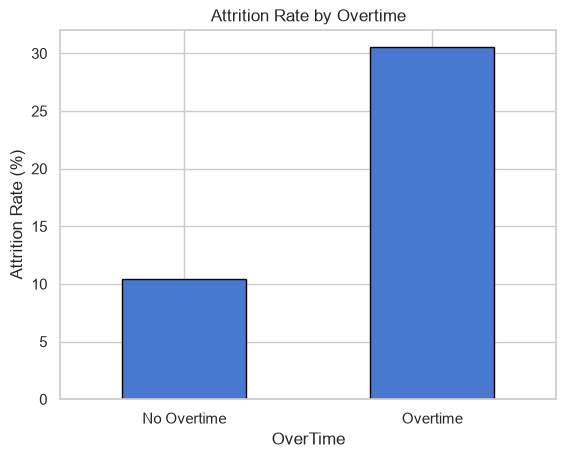

In [27]:
ot = df.groupby('OverTime')['Attrition'].mean() * 100

ot.plot(kind='bar', edgecolor='black')
plt.title('Attrition Rate by Overtime')
plt.ylabel('Attrition Rate (%)')
plt.xticks([0, 1], ['No Overtime', 'Overtime'], rotation=0)
plt.show()

### Overtime vs Attrition
- Attrition rate with no overtime: ~10%
- Attrition rate with overtime: ~30%
- Overtime employees leave at 3x the rate — strongest categorical signal found so far
- Insight: unmanaged overtime is a critical retention risk. Reducing or compensating 
  overtime could have immediate impact on attrition

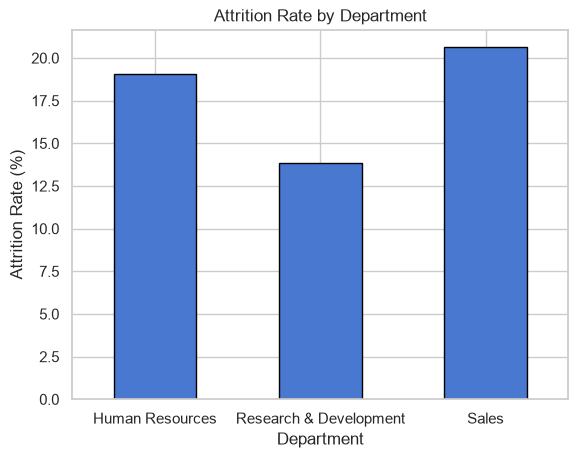

In [28]:
dept = df.groupby("Department")['Attrition'].mean() * 100
dept.plot(kind = "bar", edgecolor = 'black')
plt.title('Attrition Rate by Department')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation = 0)
plt.show()

### Attrition Rate by Department
- Sales: ~20.5% — highest attrition, likely due to target pressure and variable pay
- HR: ~19% — surprisingly high for a small department, often underpaid
- R&D: ~13.5% — most stable, likely higher pay and more engaging work
- Insight: Sales and HR need targeted retention strategies

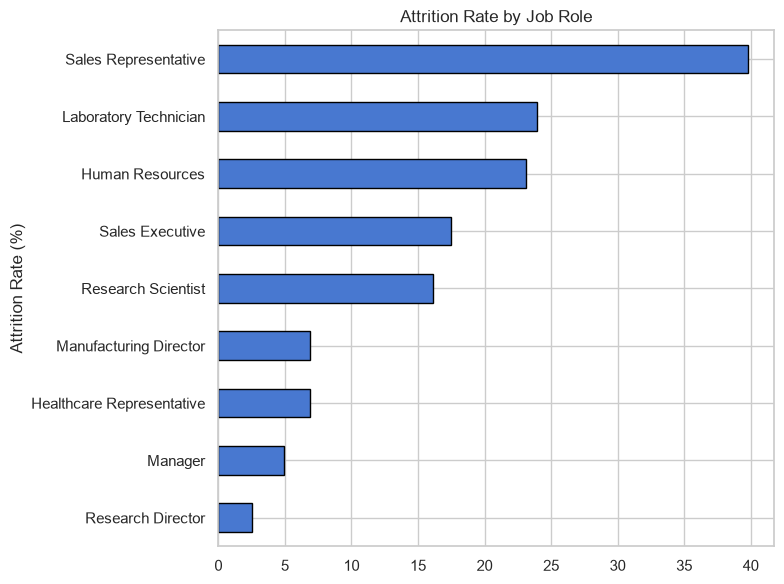

In [29]:
role = df.groupby('JobRole')['Attrition'].mean() * 100
role.sort_values().plot(kind='barh', edgecolor='black', figsize=(8, 6))
plt.title('Attrition Rate by Job Role')
plt.ylabel('Attrition Rate (%)')
plt.tight_layout()
plt.show()

### Attrition Rate by Job Role
- Highest: Sales Representative — junior, high pressure, low base pay
- Lowest: Research Director — senior, high pay, experienced and settled
- Insight: attrition is concentrated in junior and sales-facing roles

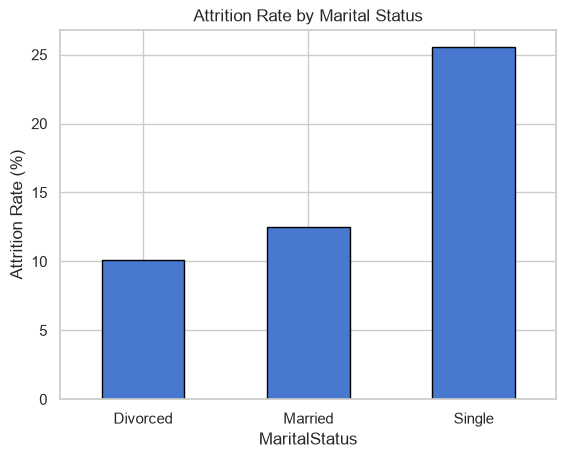

In [30]:
marital = df.groupby('MaritalStatus')['Attrition'].mean() * 100

marital.plot(kind='bar', edgecolor='black')
plt.title('Attrition Rate by Marital Status')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=0)
plt.show()

### Attrition Rate by Marital Status
- Singles: highest attrition — fewer financial responsibilities, higher risk tolerance
- Divorced: lowest attrition — financial obligations drive stability
- Married: middle ground
- Insight: life stage and financial responsibility directly influence attrition risk

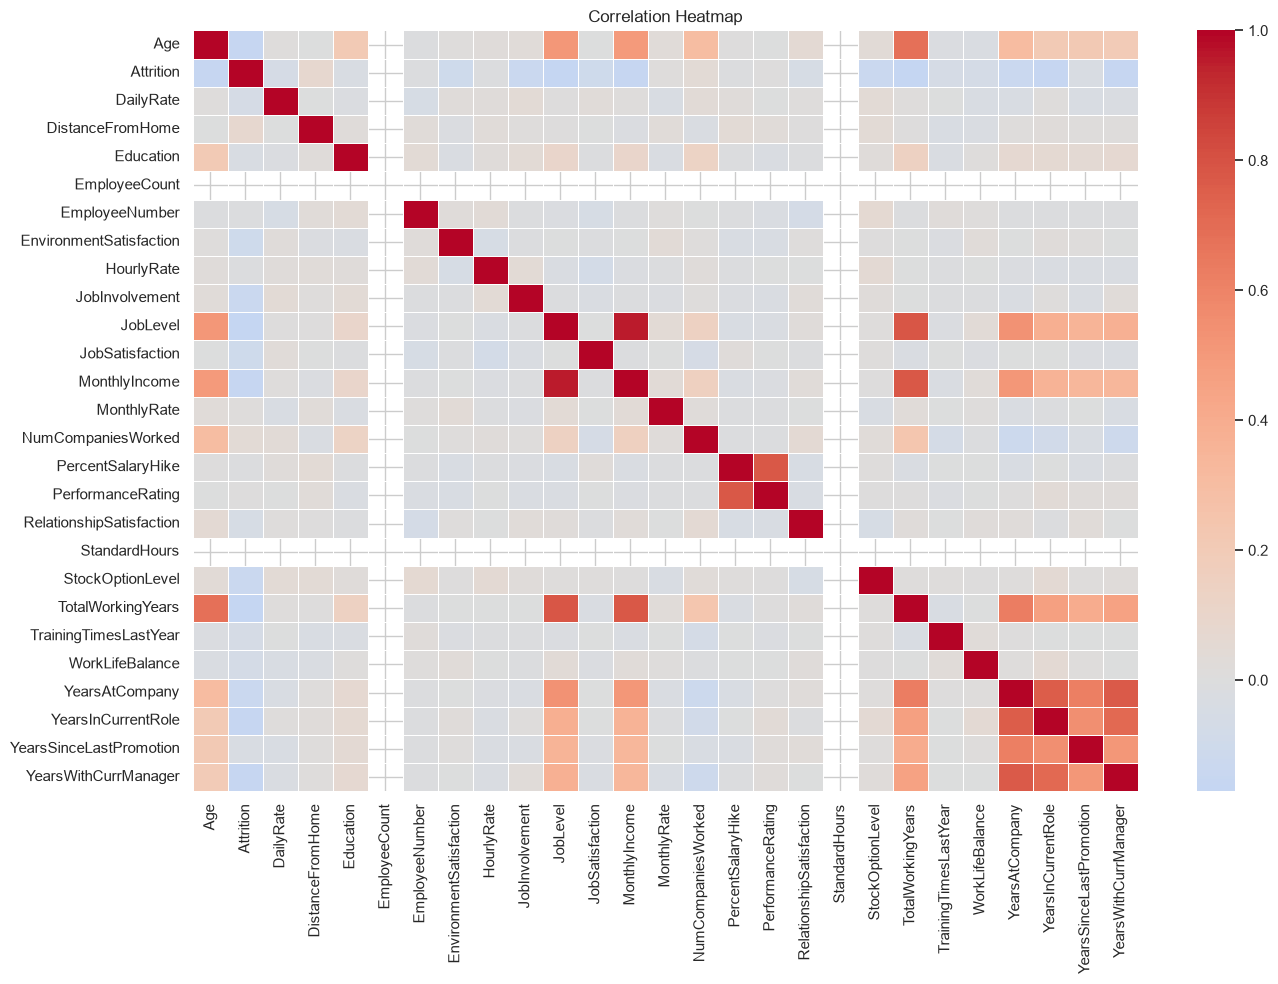

In [31]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(numeric_only=True), 
            #annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            linewidths=0.5
           )
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Correlation Heatmap Findings
- JobLevel and MonthlyIncome are highly correlated — measuring seniority from two angles
- PercentSalaryHike and PerformanceRating are highly correlated — performance drives raises
- YearsAtCompany, YearsInCurrentRole, YearsWithCurrManager form a multicollinearity cluster
- These pairs will need to be handled during feature selection to avoid redundancy in modelling

In [32]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [33]:
cols_to_drop = ['EmployeeCount', 'StandardHours', 'Over18', 'EmployeeNumber']
df = df.drop(columns=cols_to_drop)
print("Remaining columns:", df.shape[1])

Remaining columns: 31


In [34]:
df['Gender']

0       Female
1         Male
2         Male
3       Female
4         Male
         ...  
1465      Male
1466      Male
1467      Male
1468      Male
1469      Male
Name: Gender, Length: 1470, dtype: str

In [35]:
df['Gender'] = df['Gender'].map({'Male': 1, 'Female': 0})
df['OverTime'] = df['OverTime'].map({'Yes': 1, 'No': 0})

print(df['Gender'].value_counts())
print(df['OverTime'].value_counts())

Gender
1    882
0    588
Name: count, dtype: int64
OverTime
0    1054
1     416
Name: count, dtype: int64


In [36]:
cat_cols = ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']
df = pd.get_dummies(df, columns = cat_cols, drop_first = True)
print(df.shape)

(1470, 45)


In [37]:
df['MonthlyIncome_log'] = np.log(df['MonthlyIncome'])

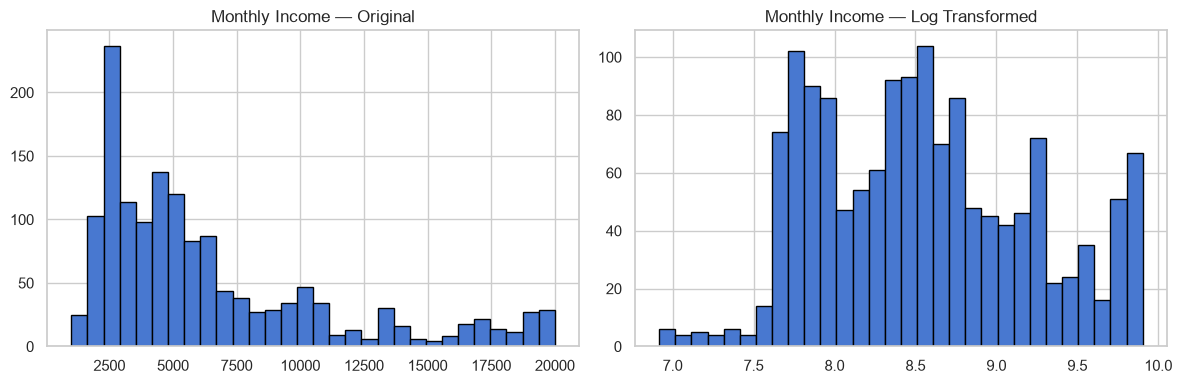

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['MonthlyIncome'], bins=30, edgecolor='black')
axes[0].set_title('Monthly Income — Original')

axes[1].hist(df['MonthlyIncome_log'], bins=30, edgecolor='black')
axes[1].set_title('Monthly Income — Log Transformed')

plt.tight_layout()
plt.show()

### Log Transformation — MonthlyIncome
- Original distribution was strongly positively skewed
- Log transformation produced a near-normal distribution
- MonthlyIncome_log will be used in modelling instead of the original

In [39]:
cols_to_drop2 = ['YearsInCurrentRole', 'YearsWithCurrManager', 'JobLevel', 'MonthlyIncome']
df = df.drop(columns=cols_to_drop2)
print(df.shape)

(1470, 42)


## Feature Engineering Summary
- Dropped 4 constant/ID columns
- Binary encoded: Gender, OverTime
- One-hot encoded: BusinessTravel, Department, EducationField, JobRole, MaritalStatus
- Log transformed: MonthlyIncome → MonthlyIncome_log
- Dropped multicollinear columns: YearsInCurrentRole, YearsWithCurrManager, JobLevel, MonthlyIncome
- Final dataset: 1470 rows, 42 columns — clean and ready for hypothesis testing

In [40]:
df.to_csv('data/hr_attrition_clean.csv', index=False)
print("Saved.")

Saved.


In [42]:
from scipy.stats import chi2_contingency
contingency_table = pd.crosstab(df['OverTime'], df['Attrition'])
chi2, p, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-Value: {p:.4f}")
print(f"Degrees of Freedom: {dof}")

Chi-Square Statistic: 87.5643
P-Value: 0.0000
Degrees of Freedom: 1


## Hypothesis 1 — Overtime and Attrition

**H0:** Overtime has no effect on attrition  
**H1:** Employees working overtime have higher attrition rates

- Chi-Square Statistic: 87.56
- P-Value: 0.0000
- Degrees of Freedom: 1

**Result:** p-value < 0.05 — reject H0  
**Conclusion:** There is a statistically significant relationship between overtime 
and attrition. Overtime employees leave at 3x the rate (30.5% vs 10.4%). 
This is the strongest categorical predictor of attrition in the dataset.

In [44]:
from scipy.stats import ttest_ind

stayed = df[df['Attrition'] == 0]['MonthlyIncome_log']
left = df[df['Attrition'] == 1]['MonthlyIncome_log']

t_stat, p_value = ttest_ind(stayed, left)

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

T-Statistic: 7.7481
P-Value: 0.0000


## Hypothesis 2 — Monthly Income and Attrition

**H0:** Monthly income has no effect on attrition  
**H1:** Employees with lower monthly income have higher attrition rates

- T-Statistic: 7.7481
- P-Value: 0.0000

**Result:** p-value < 0.05 — reject H0  
**Conclusion:** The difference in mean income between employees who stayed and 
those who left is statistically significant. Lower income is a proven driver 
of attrition in this dataset.

In [49]:
stayed_dist = df[df['Attrition'] == 0] ['DistanceFromHome']
left_dist = df[df['Attrition'] == 1] ['DistanceFromHome']

t_stat_d, p_value_d = ttest_ind(stayed_dist, left_dist)
print(f"T-Statistic: {t_stat_d:.4f}")
print(f"P-Value: {p_value_d:.4f}")

T-Statistic: -2.9947
P-Value: 0.0028


## Hypothesis 3 — Distance From Home and Attrition

**H0:** Distance from home has no effect on attrition  
**H1:** Employees living farther from office have higher attrition rates

- T-Statistic: -2.9947
- P-Value: 0.0028

**Result:** p-value < 0.05 — reject H0  
**Conclusion:** Employees who left live farther from the office on average. 
The negative t-statistic confirms leavers have greater distances. 
Effect is statistically significant but weaker than income and overtime — 
distance is a contributing factor, not a primary driver of attrition.

In [50]:
import numpy as np

def cohens_d(group1, group2):
    diff = group1.mean() - group2.mean()
    pooled_std = np.sqrt((group1.std()**2 + group2.std()**2) / 2)
    return diff / pooled_std

d = cohens_d(stayed, left)
print(f"Cohen's d: {d:.4f}")

Cohen's d: 0.5534


In [51]:
d_dist = cohens_d(stayed_dist, left_dist)
print(f"Cohen's d (Distance): {d_dist:.4f}")

Cohen's d (Distance): -0.2085


## Hypothesis 2 — Monthly Income and Attrition
- T-Statistic: 7.7481 | P-Value: 1.73e-14 | Cohen's d: 0.55 (medium effect)
- Result: Reject H0
- Conclusion: Income difference between leavers and stayers is statistically 
  significant and practically meaningful. Medium effect size confirms this is 
  a real driver, not a statistical artifact.

## Hypothesis 3 — Distance From Home and Attrition
- T-Statistic: -2.9947 | P-Value: 0.0028 | Cohen's d: -0.21 (small effect)
- Result: Reject H0
- Conclusion: Leavers live farther away on average. Statistically significant 
  but small effect — a contributing factor, not a primary driver.

In [52]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Attrition'])
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)
print("\nTrain attrition rate:", round(y_train.mean() * 100, 1), "%")
print("Test attrition rate:", round(y_test.mean() * 100, 1), "%")

Train size: (1176, 41)
Test size: (294, 41)

Train attrition rate: 16.2 %
Test attrition rate: 16.0 %


In [53]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete.")
print("Mean of first feature in train:", round(X_train_scaled[:, 0].mean(), 4))
print("Std of first feature in train:", round(X_train_scaled[:, 0].std(), 4))

Scaling complete.
Mean of first feature in train: -0.0
Std of first feature in train: 1.0


In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print(classification_report(y_test, y_pred, target_names=['Stayed', 'Left']))

              precision    recall  f1-score   support

      Stayed       0.89      0.97      0.93       247
        Left       0.69      0.38      0.49        47

    accuracy                           0.87       294
   macro avg       0.79      0.68      0.71       294
weighted avg       0.86      0.87      0.86       294



## ML Baseline — Logistic Regression

- Train/Test split: 80/20 with stratification
- Scaling: StandardScaler (fit on train only)

| Metric | Stayed | Left |
|---|---|---|
| Precision | 0.89 | 0.69 |
| Recall | 0.97 | 0.38 |
| F1-Score | 0.93 | 0.49 |

- Overall accuracy: 87% — misleading due to class imbalance
- Recall for leavers is only 38% — model misses 62% of actual attrition cases
- Root cause: class imbalance (84/16 split) biases model toward majority class


## Conclusions and Key Takeaways

### Key Findings
1. Employees earning below the company median income are significantly more 
   likely to leave — compensation is the strongest continuous predictor of attrition
2. Employees working overtime leave at 3x the rate of those who don't — 
   the strongest overall predictor found in this analysis
3. Longer commutes correlate with higher attrition — though a smaller effect 
   than income and overtime
4. Single employees leave at significantly higher rates than married or divorced 
   employees — life stage and financial responsibility influence retention

### Statistical Conclusions
- All 3 hypotheses were statistically significant (p < 0.05)
- Overtime showed the strongest categorical relationship (Chi-Square: 87.56)
- Income showed medium practical effect (Cohen's d: 0.55)
- Distance showed small practical effect (Cohen's d: 0.21)

### Model Performance
- Baseline Logistic Regression achieved 87% accuracy but only 38% recall on leavers
- Class imbalance (84/16) is the primary limitation of the current model

### Next Steps
1. Apply SMOTE or class_weight='balanced' to address class imbalance
2. Try Random Forest or XGBoost for better minority class performance
3. Collect additional features — manager relationship quality, career growth 
   opportunities, team culture scores
4. Build a real-time attrition risk scoring system for HR intervention